<a href="https://colab.research.google.com/github/KIMOOZ72/Computer-vision-projects-/blob/main/Lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

A = cv2.cvtColor(cv2.imread('face1.jpg'), cv2.COLOR_BGR2GRAY).astype(np.float64)
B = cv2.cvtColor(cv2.imread('face2.jpg'), cv2.COLOR_BGR2GRAY).astype(np.float64)

if A.shape != B.shape:
    B = cv2.resize(
        B,
        (A.shape[1], A.shape[0]),
        interpolation=cv2.INTER_LINEAR
    )


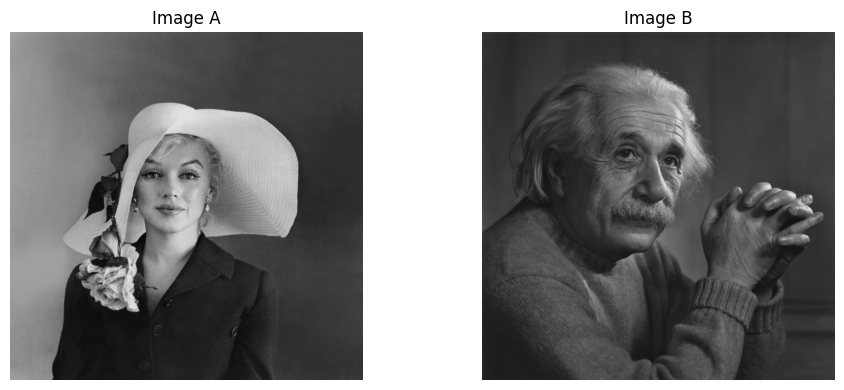

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title("Image A")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(B, cmap="gray", vmin=0, vmax=255)
plt.title("Image B")
plt.axis("off")

plt.tight_layout()
plt.show()

Level 1: (1168, 1184)
Level 2: (584, 592)
Level 3: (292, 296)
Level 4: (146, 148)
Level 5: (73, 74)


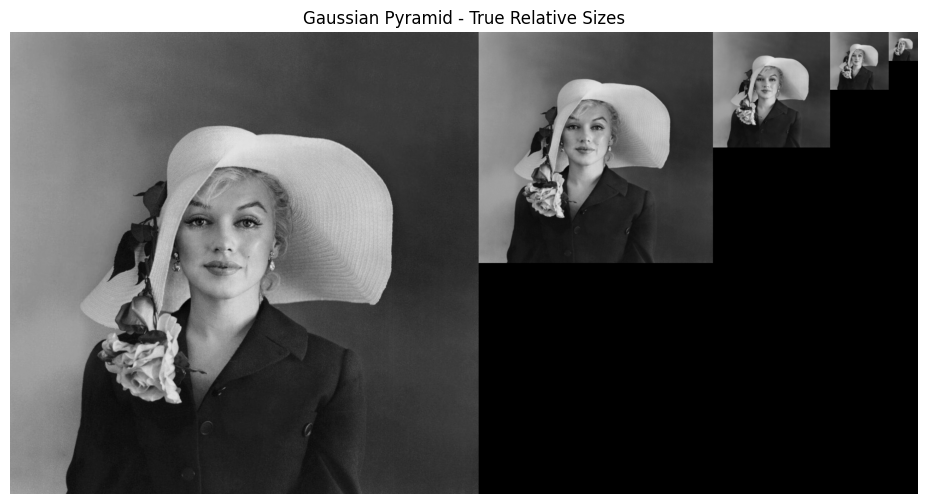

In [ ]:

levels = 5

gaussian_pyramid = [A]


for i in range(levels - 1):

    previous = gaussian_pyramid[-1]
    smaller = cv2.pyrDown(previous)

    gaussian_pyramid.append(smaller)

for i, image in enumerate(gaussian_pyramid):
    print(f"Level {(i+1)}: {image.shape}")

heights = [image.shape[0] for image in gaussian_pyramid]
widths = [image.shape[1] for image in gaussian_pyramid]

canvas_height = max(heights)
canvas_width = sum(widths)

canvas = np.zeros(
    (canvas_height, canvas_width),
    dtype=np.float64
)

x_offset = 0

for image in gaussian_pyramid:

    h, w = image.shape

    canvas[0:h, x_offset:x_offset + w] = image

    x_offset += w

plt.figure(figsize=(15, 6))
plt.imshow(canvas, cmap="gray", vmin=0, vmax=255)
plt.title("Gaussian Pyramid - True Relative Sizes")
plt.axis("off")
plt.show()

In [ ]:
def laplacian_pyramid(img, levels=5):
    gp = [img]
    for i in range(levels - 1):
        gp.append(cv2.pyrDown(gp[-1]))

    lp = []
    for i in range(levels - 1):
        up = cv2.pyrUp(
            gp[i + 1],
            dstsize=(gp[i].shape[1], gp[i].shape[0])
        )

        detail = gp[i] - up

        lp.append(detail)

    lp.append(gp[-1])

    return lp


laplacian_levels = laplacian_pyramid(A, levels=5)

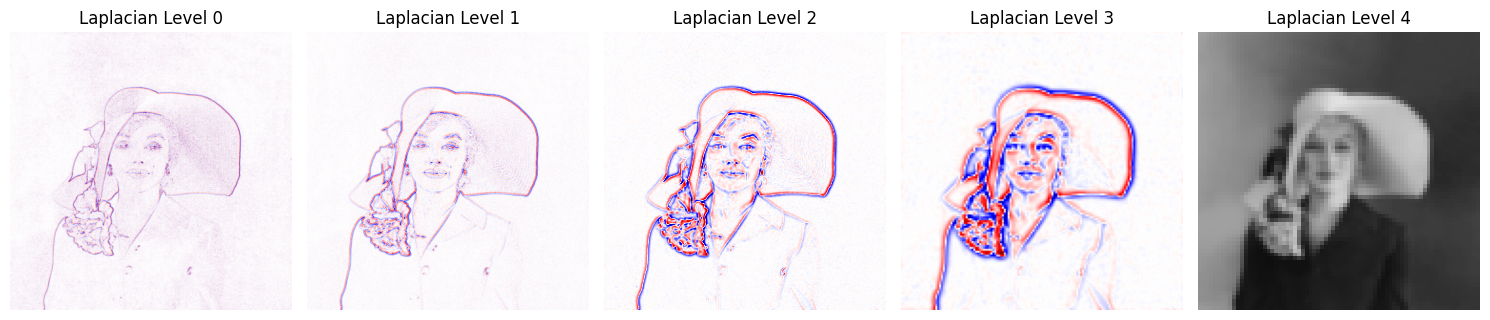

In [ ]:
plt.figure(figsize=(15, 5))

for i, image in enumerate(laplacian_levels):

    plt.subplot(1, 5, i + 1)

    if i < len(laplacian_levels) - 1:

        max_value = np.max(np.abs(image))

        plt.imshow(
            image,
            cmap="seismic",
            vmin=-max_value,
            vmax=max_value
        )

    else:
        plt.imshow(image, cmap="gray", vmin=0, vmax=255)

    plt.title(f"Laplacian Level {i}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def reconstruct(lp):
    img = lp[-1]
    for L in reversed(lp[:-1]):
        img = cv2.pyrUp(
            img,
            dstsize=(L.shape[1], L.shape[0])
        ) + L

    return img


reconstructed = reconstruct(laplacian_levels)
max_error = np.max(np.abs(A - reconstructed))

print("Maximum Absolute Error:", max_error)

Maximum Absolute Error: 0.0


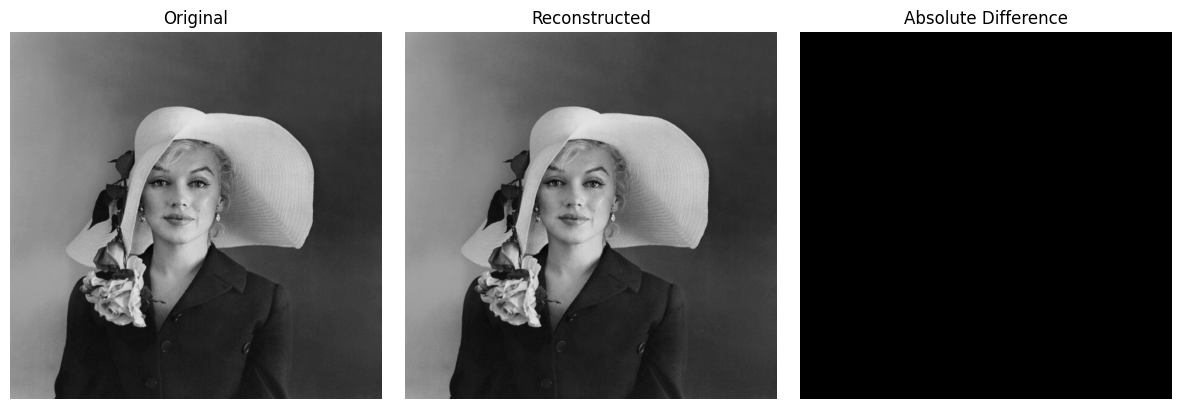

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(reconstructed, cmap="gray", vmin=0, vmax=255)
plt.title("Reconstructed")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(np.abs(A - reconstructed), cmap="gray")
plt.title("Absolute Difference")
plt.axis("off")

plt.tight_layout()
plt.show()

Each Laplacian level contains the image details lost between two consecutive Gaussian pyramid levels. These details include edges and textures at different scales. By expanding the smallest Gaussian level and adding the stored Laplacian details, the original image can be reconstructed with approximately zero error

In [ ]:
natural = cv2.imread("/content/nature.jpg", cv2.IMREAD_GRAYSCALE).astype(np.float64)
texture = cv2.imread("/content/texture.jpg", cv2.IMREAD_GRAYSCALE).astype(np.float64)

In [ ]:
def spectrum(g):

    F = np.fft.fftshift(np.fft.fft2(g))
    return 20* np.log(np.abs(F)+1)

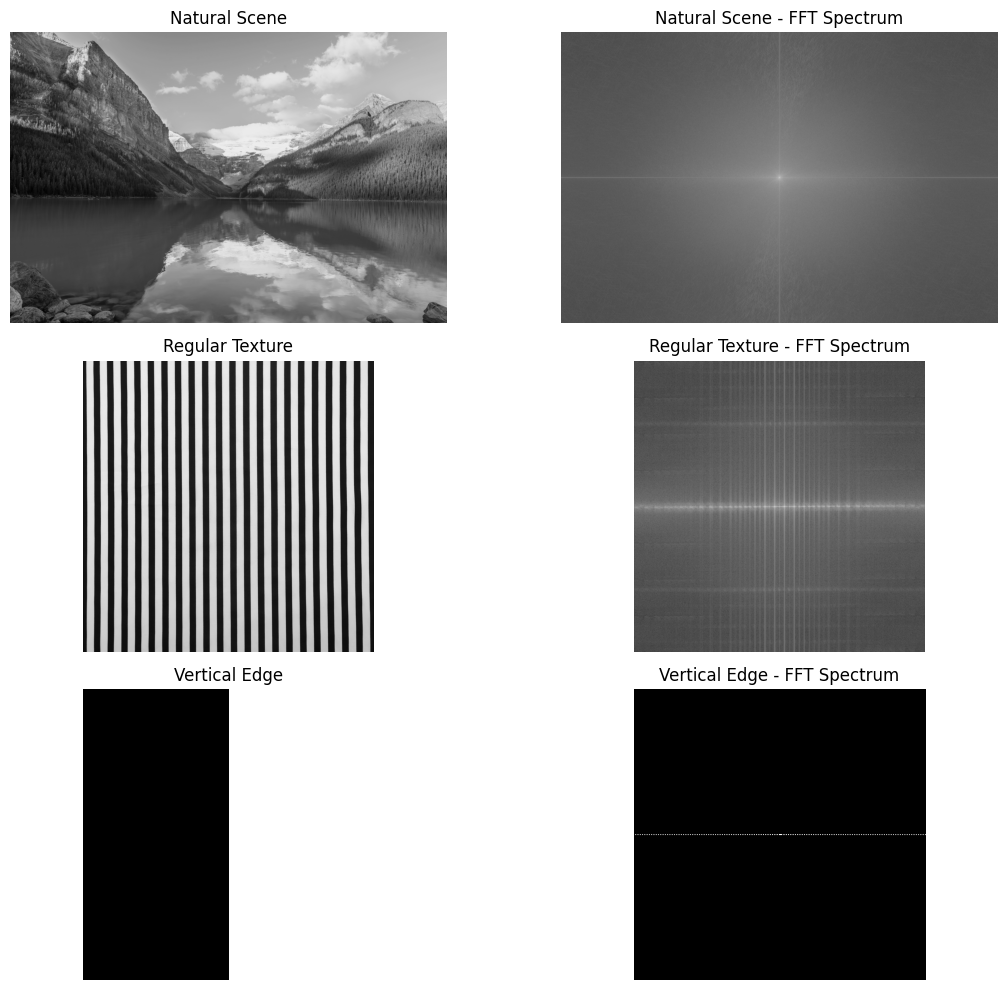

In [ ]:
edge_image = np.zeros((256, 256), dtype=np.float64)
edge_image[:, 128:] = 255
images = [natural, texture, edge_image]

titles = [
    "Natural Scene",
    "Regular Texture",
    "Vertical Edge"
]

plt.figure(figsize=(12, 10))

for i, image in enumerate(images):

    plt.subplot(3, 2, 2 * i + 1)

    plt.imshow(image, cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

    plt.subplot(3, 2, 2 * i + 2)

    plt.imshow(spectrum(image), cmap="gray")
    plt.title(titles[i] + " - FFT Spectrum")
    plt.axis("off")

plt.tight_layout()
plt.show()

The natural scene generally has strong energy near the center of the spectrum because low spatial frequencies represent smooth regions and large-scale image structures.

The regular texture produces distinct peaks or repeated structures in the spectrum because periodic image patterns correspond to specific spatial frequencies.

The vertical edge produces a strong horizontal frequency structure because the intensity changes across the edge, perpendicular to its orientation.

In [ ]:
def circular_masks(shape, radius):
    h, w = shape
    center_y = h // 2
    center_x = w // 2

    Y, X = np.ogrid[:h, :w]


    distance_squared = (
        (X - center_x) ** 2 +
        (Y - center_y) ** 2
    )
    low_mask = (
        distance_squared <= radius ** 2
    ).astype(np.float64)

    high_mask = 1.0 - low_mask

    return low_mask, high_mask

In [ ]:
def frequency_filter(image, radius):

    F = np.fft.fft2(image)

    Fs = np.fft.fftshift(F)

    low_mask, high_mask = circular_masks(
        image.shape,
        radius
    )

    low_spectrum = Fs * low_mask
    high_spectrum = Fs * high_mask

    low_unshifted = np.fft.ifftshift(low_spectrum)
    high_unshifted = np.fft.ifftshift(high_spectrum)

    low_image = np.real(np.fft.ifft2(low_unshifted))
    high_image = np.real(np.fft.ifft2(high_unshifted))

    return low_image, high_image, low_mask, high_mask

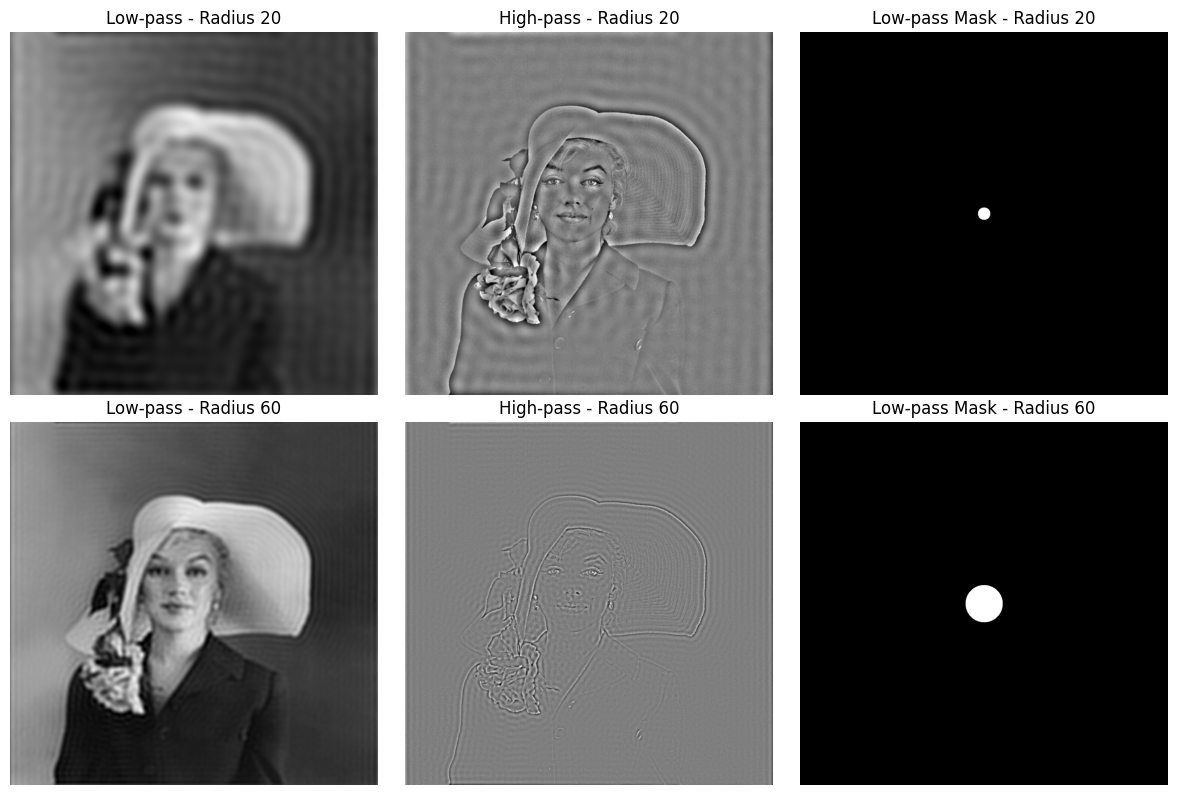

In [ ]:
radii = [20, 60]

plt.figure(figsize=(12, 8))

for i, radius in enumerate(radii):

    low, high, low_mask, high_mask = frequency_filter(
        A,
        radius
    )

    plt.subplot(2, 3, 3 * i + 1)
    plt.imshow(low, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Low-pass - Radius {radius}")
    plt.axis("off")

    plt.subplot(2, 3, 3 * i + 2)
    plt.imshow(high, cmap="gray", vmin=-100, vmax=100)
    plt.title(f"High-pass - Radius {radius}")
    plt.axis("off")

    plt.subplot(2, 3, 3 * i + 3)
    plt.imshow(low_mask, cmap="gray")
    plt.title(f"Low-pass Mask - Radius {radius}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Low-pass filtering in the frequency domain smooths the image by attenuating high spatial frequencies. This is conceptually similar to Gaussian blur because spatial convolution corresponds to frequency-domain multiplication. However, an ideal circular mask has a sharp cutoff and may introduce ringing artifacts, unlike the smoother Gaussian frequency response